# 02 - Baselines and manual tuning (Step 2)

A narrative view of the Step 2 results. Everything shown is read from files that
`scripts/run_tuning.py` generated from `reports/experiments.jsonl`. Nothing is computed or typed here.

In [1]:
# Make the project root importable when the notebook is opened from notebooks/.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import pandas as pd
from IPython.display import Image, display

import config
from src.logging_utils import read_experiments

summary = pd.read_csv(config.TABLES / f"tuning_summary{config.RUN_SUFFIX}.csv")
print(f"quick={config.QUICK}")

quick=False


## The methods

| Method | What it is | Why it is here |
|---|---|---|
| `lgbm_default` | LightGBM with library defaults | the "no tuning" reference |
| `logreg` | Logistic regression on standardized features | a sanity floor: a linear model should be clearly worse |
| `grid` | Grid Search: 3 x 3 x 2 x 2 = 36 points over num_leaves, learning_rate, min_child_samples, feature_fraction | exhaustive over a few hand-picked values |
| `random` | Random Search: 36 seeded samples from a 6-parameter space | the standard strong baseline for tuning |
| `optuna` | Optuna TPE: 36 trials with a seeded sampler, same 6-parameter space | model-based search. Its first 10 trials are random and equal Random Search's first 10 |

**Equal budget:** every tuning method evaluates 36 configurations. Each one runs on the same 3
persisted CV folds of the same 60k tuning subset of `train`, with the same cap on boosting rounds
and the same early stopping. Wall-clock time is reported but not capped. Random and Optuna share
their first 10 trials (TPE's seeded random start-up), so any efficiency difference between them comes
from the other 26 trials.

**Refit (version 2):** the best configuration is refit once on all of `train` with a fixed number of
trees, the mean of its CV folds' best iterations (no hold-out, no early stopping), and scored once on
`test_random` and once on `test_future`. The full reasoning is in `reports/tuning_writeup.md`.

## Summary table

CV AUC is measured on the tuning folds. The test columns come from the single final scoring of each
refit model, with 95% paired bootstrap CIs (`*_ci_low`, `*_ci_high`) computed from the saved test-set
predictions. `tpr_at_1pct_fpr` is the security-relevant number: how much malware is caught when at
most 1% of benign files raise an alarm. Compare the `test_random` and `test_future` columns: the gap
is the overstatement the research question asks about.

In [3]:
summary

,method,model,refit_version,n_trials,best_cv_auc,cv_auc_std,test_random_n,test_random_roc_auc,test_random_roc_auc_ci_low,test_random_roc_auc_ci_high,...,tpr_gap_ci_high,search_seconds,seconds_per_trial,fit_seconds,train_rows,refit_n_estimators,cv_mean_best_iteration,cv_folds_at_round_cap,folds_hash,run_id
0,lgbm_default,lightgbm,2,NaN,0.996770,0.000195,40000,0.997816,0.997526,0.998077,...,0.020195,NaN,NaN,24.904160,160000,NaN,NaN,NaN,ad0bf89e4b0e9d6d,20261028T080109Z-d9f409
1,logreg,logistic_regression,2,NaN,0.984170,0.000413,40000,0.992858,0.992080,0.993582,...,0.111679,NaN,NaN,19.805226,160000,NaN,NaN,NaN,ad0bf89e4b0e9d6d,20261028T080109Z-d9f409
2,grid,lightgbm,2,36.0,0.997697,0.000288,40000,0.999057,0.998865,0.999214,...,0.016561,6800.825725,188.911826,196.230795,160000,719.0,718.666667,0.0,ad0bf89e4b0e9d6d,20261028T080109Z-d9f409
3,random,lightgbm,2,36.0,0.997704,0.000193,40000,0.999012,0.998840,0.999162,...,0.014082,5353.326561,148.703516,95.964145,160000,739.0,738.666667,0.0,ad0bf89e4b0e9d6d,20261028T080109Z-d9f409
4,optuna,lightgbm,2,36.0,0.997774,0.000250,40000,0.999115,0.998944,0.999271,...,0.014648,4455.468613,123.763017,106.726604,160000,609.0,608.666667,0.0,ad0bf89e4b0e9d6d,20261028T080109Z-d9f409


## Is one tuner really better?

Paired bootstrap differences (method a minus method b, same resampled rows for both). A difference
is significant at 95% only when its CI excludes zero. The generated write-up turns this table into
the verdict on which tuner won.

In [4]:
pairwise = pd.read_csv(config.TABLES / f"tuning_pairwise{config.RUN_SUFFIX}.csv")
pairwise

,test_set,metric,method_a,method_b,diff_a_minus_b,ci_low,ci_high,share_resamples_a_better,significant_95
0,test_random,roc_auc,optuna,random,0.000103,0.000037,0.000176,0.997,True
1,test_random,roc_auc,optuna,grid,0.000058,-0.000024,0.000143,0.919,False
2,test_random,roc_auc,random,grid,-0.000045,-0.000138,0.000037,0.158,False
3,test_random,roc_auc,grid,lgbm_default,0.001240,0.001043,0.001450,1.000,True
4,test_random,roc_auc,random,lgbm_default,0.001196,0.001017,0.001407,1.000,True
5,test_random,roc_auc,optuna,lgbm_default,0.001298,0.001114,0.001514,1.000,True
6,test_random,tpr_at_1pct_fpr,optuna,random,0.002150,0.000554,0.003264,0.998,True
7,test_random,tpr_at_1pct_fpr,optuna,grid,0.000750,-0.000548,0.002125,0.848,False
8,test_random,tpr_at_1pct_fpr,random,grid,-0.001400,-0.002672,0.000404,0.072,False
9,test_random,tpr_at_1pct_fpr,grid,lgbm_default,0.021046,0.017366,0.023640,1.000,True


## Comparison across methods

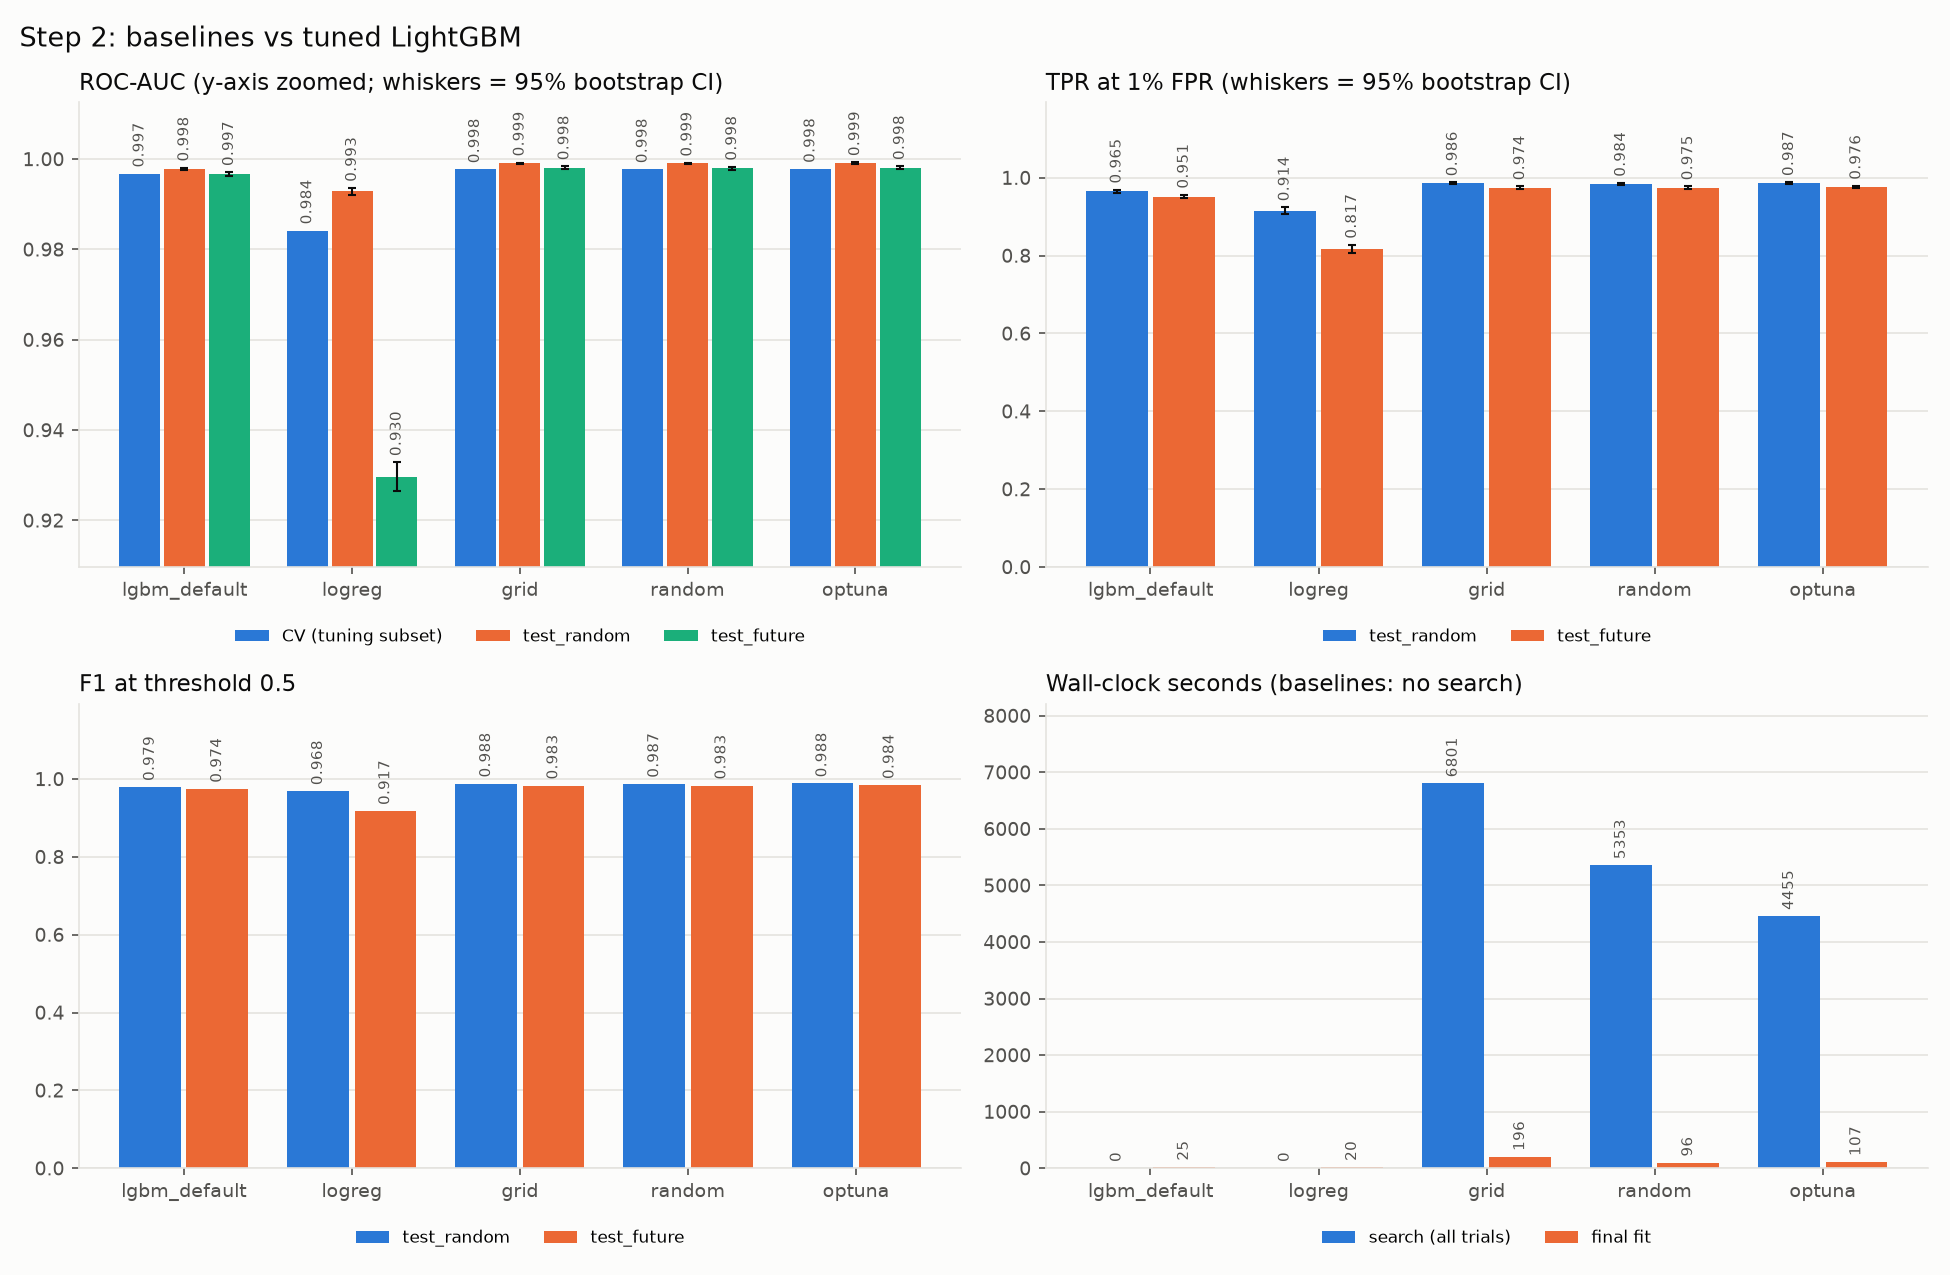

In [5]:
display(Image(filename=str(config.FIGURES / f"tuning_compare{config.RUN_SUFFIX}.png")))

## Convergence

Best CV AUC so far against trial number, for each tuner. For Grid, the curve shows when the grid
order happens to reach good points, not a search effect. Random and Optuna are identical for the
first 10 trials by construction (shaded band, see above). `tuning_trials.csv` flags trials whose
training ended at the round cap (`hit_round_cap`).

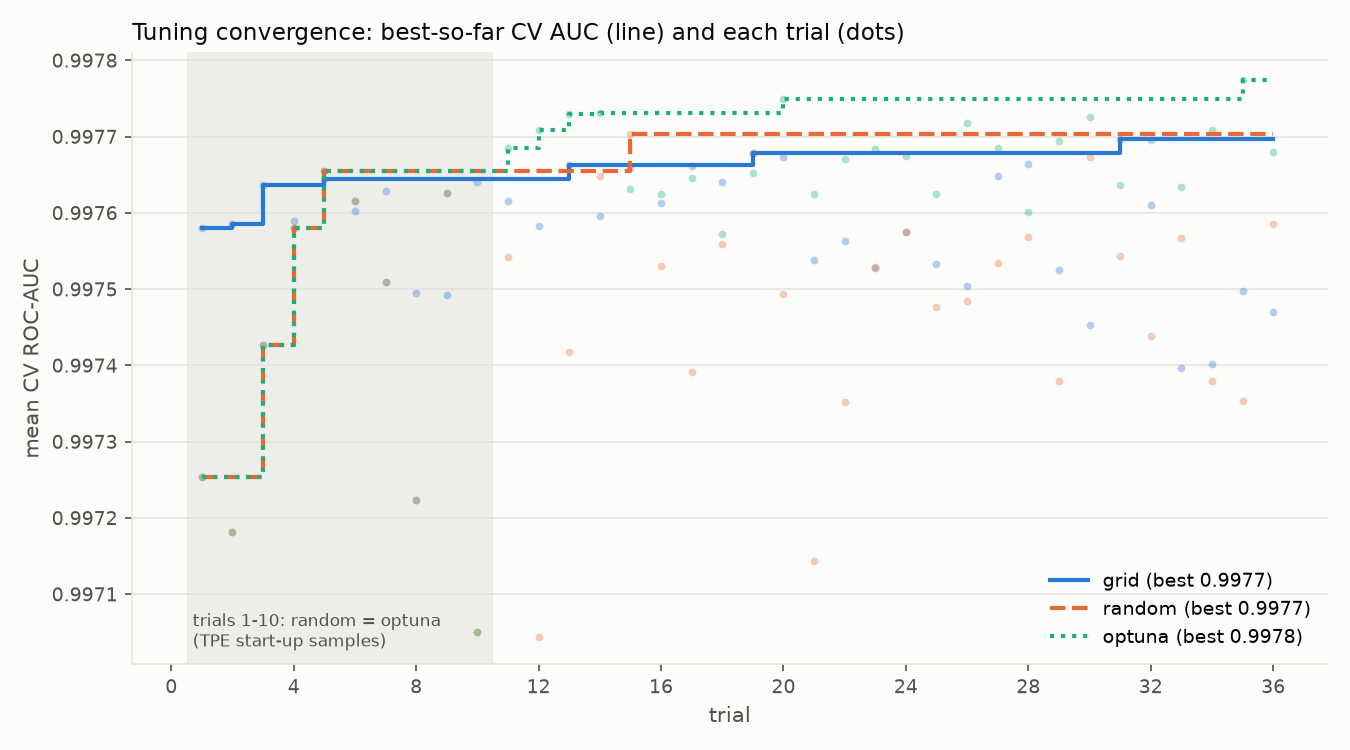

In [6]:
display(Image(filename=str(config.FIGURES / f"tuning_convergence{config.RUN_SUFFIX}.png")))

## Raw trial log

Every trial is one line in the experiment log. As a quick completeness check, this counts the
records each method wrote in the current mode.

In [7]:
log = read_experiments()
if not log.empty:
    log = log[(log["step"] == "tuning") & (log["quick"] == config.QUICK)]
    display(log.groupby(["method", "kind"]).size().unstack(fill_value=0))

kind,final_eval,tune_search,tune_trial
method,,,
grid,2,1,36
lgbm_default,3,0,0
logreg,3,0,0
optuna,2,1,36
random,2,1,36
